# Praktikum Machine Learning: Klasifikasi Pay Band

**Nama:** [Hilal Tsabitul Azmi Arba'i]

**NRP:** [5054251008]

Template Kaggle Competition Praktikum Machine Learning (materi Klasifikasi).

https://chat.deepseek.com/share/9q3af9foc3mklf18qy

## Setup

In [22]:
# Import Library
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
# tambahan library yang mungkin diperlukan
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

## Load Data

In [23]:
# Sesuaikan path dengan lokasi file kalian (Kaggle: /kaggle/input/<nama-kompetisi>/...)
df_train = pd.read_csv('train (4).csv')
df_test = pd.read_csv('test (2).csv')

print("Train Data Shape:", df_train.shape)
print("Test Data Shape:", df_test.shape)

df_train.head(50)

Train Data Shape: (60430, 21)
Test Data Shape: (29070, 20)


,employee_id,source_dataset,import_batch,age,gender,ethnicity,education_level,years_experience,tenure_years,department,...,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,record_hash,notes,pay_band
0,EMP-194754,hris_export_2023,24,NaN,?,NaN,bachelor's degree,NaN,6.0,Engineering,...,PH,Hybrid,exceeds,3.1,04-30-2020,PHP,"191,210 per month",fedab652e9c8,NaN,Band 2
1,EMP-109967,hris_export_2023,22,0.0,female,White,Associate Degree,24.0,0.0,IT,...,Brazil,On site,Meets Expectations,4.1,02 Apr 2026,BRL,"BRL 250,722",a94720bee9e0,NaN,Band 2
2,EMP-128419,hris_export_2023,8,33.0,FEMALE,unknown,PhD,12.0,1.0,Legal,...,United Kingdom,Remote,Meets Expectations,2.1,23 Dec 2024,?,"28,276.28",8f8b484b87ee,NaN,Band 1
3,EMP-108690,hris_export_2023,39,NaN,Woman,Asian,PhD,20.0,4.0,Legal,...,Brazil,On-site,Meets Expectations,4.1,2022-07-20,BRL,18315 monthly,a7a6d7f3cc91,NaN,Band 1
4,EMP-169742,acquired_company_legacy,22,39.0,Other,White,bachelor's degree,-1.0,4.0,Data Science Department,...,USA,Hybrid,NaN,3.5,"March 31, 2022",USD,"20.855,27 USD",7826c5135f34,NaN,Band 1
5,EMP-189049,acquired_company_legacy,13,NaN,Woman,Black or African American,MSc,-1.0,2.0,Legal Department,...,France,Remote,NaN,4.4,2024-07-17,EUR,20620,75ca4e7688bc,TBD,Band 1
6,EMP-125167,survey_response_2024,14,NaN,NaN,White,BSc,24.0,4.0,Sales,...,France,Onsite,Exceeds Expectations,3.4,18 Feb 2022,EUR,"48,455.37",1a5c9dcb6761,NaN,Band 3
7,EMP-128093,acquired_company_legacy,19,54.0,M,Black or African American,BSc,31.0,5.0,Operations,...,Kenya,Onsite,Meets Expectations,4.8,02-20-2021,KES,"8,924,798 KES",f4728e19d94c,NaN,Band 3
8,EMP-109731,acquired_company_legacy,20,54.0,F,Black or African American,bachelor's degree,NaN,8.0,Operations,...,US,Onsite,exceeds,2.8,2017-07-01,USD,"4,177 per month",50c8a6e3b611,NaN,Band 3
9,EMP-196010,hris_export_2023,7,20.0,F,White,PhD.,NaN,0.0,HR,...,Brazil,On-site,exceeds,2.8,08 Aug 2026,BRL,"18,969 per month",2d5bcb1e0e1f,NaN,Band 2


## Exploratory Data Analysis

Lengkapi bagian ini sesuai dengan **EDA** yang kalian lakukan.

In [24]:
col_gakpenting = ['employee_id', "record_hash", "ethnicity", "hire_date", "age", "gender", "performance_review_score", "years_experience", "notes", "salary_raw"]

In [25]:
display(df_train.describe())
display(df_train.info())
display(df_train.isnull().sum().sort_values(ascending=False))

,import_batch,age,years_experience,tenure_years,performance_review_score
count,60430.000000,40919.000000,38853.000000,59842.000000,50784.000000
mean,19.983336,51.406510,50.295524,2.806708,8.522141
std,11.277795,118.804996,187.232439,2.707436,18.107695
min,1.000000,-1.000000,-1.000000,-12.000000,1.000000
25%,10.000000,30.000000,6.000000,1.000000,2.900000
50%,20.000000,36.000000,14.000000,3.000000,3.500000
75%,30.000000,43.000000,21.000000,5.000000,4.200000
max,39.000000,999.000000,999.000000,16.000000,100.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60430 entries, 0 to 60429
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   employee_id               60430 non-null  object 
 1   source_dataset            60430 non-null  object 
 2   import_batch              60430 non-null  int64  
 3   age                       40919 non-null  float64
 4   gender                    59078 non-null  object 
 5   ethnicity                 49033 non-null  object 
 6   education_level           58188 non-null  object 
 7   years_experience          38853 non-null  float64
 8   tenure_years              59842 non-null  float64
 9   department                60430 non-null  object 
 10  job_title                 59229 non-null  object 
 11  country                   60430 non-null  object 
 12  remote_status             55467 non-null  object 
 13  performance_rating        58143 non-null  object 
 14  perfor

None

notes                       54297
years_experience            21577
age                         19511
ethnicity                   11397
performance_review_score     9646
currency                     5519
remote_status                4963
performance_rating           2287
education_level              2242
gender                       1352
job_title                    1201
tenure_years                  588
employee_id                     0
source_dataset                  0
import_batch                    0
country                         0
department                      0
hire_date                       0
salary_raw                      0
record_hash                     0
pay_band                        0
dtype: int64

In [26]:
df_train = df_train.drop_duplicates()

In [27]:
df_train.head()

,employee_id,source_dataset,import_batch,age,gender,ethnicity,education_level,years_experience,tenure_years,department,...,country,remote_status,performance_rating,performance_review_score,hire_date,currency,salary_raw,record_hash,notes,pay_band
0,EMP-194754,hris_export_2023,24,NaN,?,NaN,bachelor's degree,NaN,6.0,Engineering,...,PH,Hybrid,exceeds,3.1,04-30-2020,PHP,"191,210 per month",fedab652e9c8,NaN,Band 2
1,EMP-109967,hris_export_2023,22,0.0,female,White,Associate Degree,24.0,0.0,IT,...,Brazil,On site,Meets Expectations,4.1,02 Apr 2026,BRL,"BRL 250,722",a94720bee9e0,NaN,Band 2
2,EMP-128419,hris_export_2023,8,33.0,FEMALE,unknown,PhD,12.0,1.0,Legal,...,United Kingdom,Remote,Meets Expectations,2.1,23 Dec 2024,?,"28,276.28",8f8b484b87ee,NaN,Band 1
3,EMP-108690,hris_export_2023,39,NaN,Woman,Asian,PhD,20.0,4.0,Legal,...,Brazil,On-site,Meets Expectations,4.1,2022-07-20,BRL,18315 monthly,a7a6d7f3cc91,NaN,Band 1
4,EMP-169742,acquired_company_legacy,22,39.0,Other,White,bachelor's degree,-1.0,4.0,Data Science Department,...,USA,Hybrid,NaN,3.5,"March 31, 2022",USD,"20.855,27 USD",7826c5135f34,NaN,Band 1


In [28]:
for col in df_train:
    print(col)
    unique_values = df_train[col].unique()
    display(unique_values)

employee_id


array(['EMP-194754', 'EMP-109967', 'EMP-128419', ..., 'EMP-131146',
       'EMP-136538', 'EMP-179655'], shape=(59589,), dtype=object)

source_dataset


array(['hris_export_2023', 'acquired_company_legacy',
       'survey_response_2024'], dtype=object)

import_batch


...

array(['fedab652e9c8', 'a94720bee9e0', '8f8b484b87ee', ...,
       'e2619f03b6de', '298452a09407', 'f247385897c3'],
      shape=(59589,), dtype=object)

notes


array([nan, 'TBD', 'migrated', 'check later', 'verified'], dtype=object)

pay_band


array(['Band 2', 'Band 1', 'Band 3', 'Band 4+'], dtype=object)

In [29]:
#df_train = df_train.drop()
df_train['gender'] = df_train['gender'].replace({'male': 'M', 'female': 'F', "woman": 'F', "man": 'M', "femal": 'F', "femal ": 'F', "mal": 'M', "Male": 'M', "Female": 'F', "MALE": 'M', "FEMALE": 'F'})

In [30]:
print("missing value pada train data:", df_train.isnull().sum())

missing value pada train data: employee_id                     0
source_dataset                  0
import_batch                    0
age                         19250
gender                       1333
ethnicity                   11245
education_level              2212
years_experience            21261
tenure_years                  576
department                      0
job_title                    1190
country                         0
remote_status                4898
performance_rating           2252
performance_review_score     9508
hire_date                       0
currency                     5447
salary_raw                      0
record_hash                     0
notes                       53544
pay_band                        0
dtype: int64


dihapus
age 
year_experiances
notes
ethnicity
peformance

In [31]:
df_train['gender'] = df_train['gender'].str.lower().str.strip()
df_train['hire_date'] = pd.to_datetime(df_train['hire_date'], errors='coerce')

In [32]:
df_train = df_train.drop(columns=col_gakpenting)

In [33]:
#df_train['salary_raw'] = pd.to_numeric(df_train['salary_raw'], errors='coerce')

In [34]:
df_train.head(50)

,source_dataset,import_batch,education_level,tenure_years,department,job_title,country,remote_status,performance_rating,currency,pay_band
0,hris_export_2023,24,bachelor's degree,6.0,Engineering,STAFF ENG.,PH,Hybrid,exceeds,PHP,Band 2
1,hris_export_2023,22,Associate Degree,0.0,IT,IT SUPPORT SPECIALIST,Brazil,On site,Meets Expectations,BRL,Band 2
2,hris_export_2023,8,PhD,1.0,Legal,Paralegal,United Kingdom,Remote,Meets Expectations,?,Band 1
3,hris_export_2023,39,PhD,4.0,Legal,paralegal,Brazil,On-site,Meets Expectations,BRL,Band 1
4,acquired_company_legacy,22,bachelor's degree,4.0,Data Science Department,ML Enginer,USA,Hybrid,NaN,USD,Band 1
5,acquired_company_legacy,13,MSc,2.0,Legal Department,General Counsel,France,Remote,NaN,EUR,Band 1
6,survey_response_2024,14,BSc,4.0,Sales,sales manager,France,Onsite,Exceeds Expectations,EUR,Band 3
7,acquired_company_legacy,19,BSc,5.0,Operations,Operations Manager,Kenya,Onsite,Meets Expectations,KES,Band 3
8,acquired_company_legacy,20,bachelor's degree,8.0,Operations,COO,US,Onsite,exceeds,USD,Band 3
9,hris_export_2023,7,PhD.,0.0,HR,HR Manager,Brazil,On-site,exceeds,BRL,Band 2


## Preprocessing

Lengkapi bagian ini sesuai dengan **Preprocessing Data** yang kalian lakukan.

In [35]:
x = df_train.drop(columns=["pay_band"])
y = df_train["pay_band"].copy()
x_test = df_test.copy()

x_test = x_test.drop(columns=col_gakpenting)

print("fitur train:", x.columns.tolist())
print("fitur test :", x_test.columns.tolist())

fitur train: ['source_dataset', 'import_batch', 'education_level', 'tenure_years', 'department', 'job_title', 'country', 'remote_status', 'performance_rating', 'currency']
fitur test : ['source_dataset', 'import_batch', 'education_level', 'tenure_years', 'department', 'job_title', 'country', 'remote_status', 'performance_rating', 'currency']


In [36]:
fitur_numerik = x.select_dtypes(include=np.number).columns.tolist()
fitur_kategorikal = x.select_dtypes(exclude=np.number).columns.tolist()

In [37]:
x_train, x_valid, y_train, y_valid = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [38]:
numerik_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

kategorikal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [39]:
transformers = []
if fitur_numerik:
    transformers.append(
        ("num", numerik_pipeline, fitur_numerik)
    )
    
if fitur_kategorikal:
    transformers.append(
        ("cat", kategorikal_pipeline, fitur_kategorikal)
    )
    
preprocessor = ColumnTransformer(
    transformers=transformers
)


## Modeling

Bebas memilih model ML (boleh *ensemble*), **asal bukan deep learning**.

**Pastikan sudah memiliki variabel berikut:**
`X_train, X_val, y_train, y_val -> df_train`

In [40]:
model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

akurasi:  0.5456452424903507
f1_score:  0.4195477855943119
              precision    recall  f1-score   support

      Band 1       0.59      0.63      0.61      3614
      Band 2       0.52      0.56      0.54      5383
      Band 3       0.53      0.46      0.49      2676
     Band 4+       0.33      0.02      0.04       245

    accuracy                           0.55     11918
   macro avg       0.49      0.42      0.42     11918
weighted avg       0.54      0.55      0.54     11918



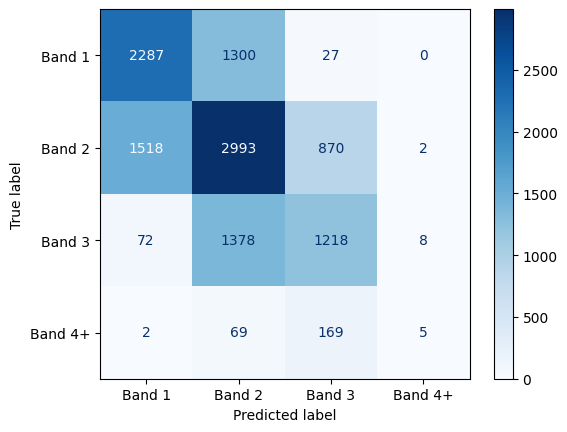

In [41]:
model_rf.fit(x_train, y_train)
valid_prediction_rf = model_rf.predict(x_valid)

print("akurasi: ", accuracy_score(y_valid, valid_prediction_rf))
print("f1_score: ", f1_score(y_valid, valid_prediction_rf, average="macro"))
print(classification_report(y_valid, valid_prediction_rf, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_prediction_rf, cmap="Blues"
)
plt.show()

In [42]:
model_knn = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors= 5
    ))
])

akurasi:  0.421882866252727
f1_score:  0.2929475489571114
              precision    recall  f1-score   support

      Band 1       0.38      0.47      0.42      3614
      Band 2       0.46      0.53      0.49      5383
      Band 3       0.38      0.19      0.25      2676
     Band 4+       0.07      0.00      0.01       245

    accuracy                           0.42     11918
   macro avg       0.32      0.30      0.29     11918
weighted avg       0.41      0.42      0.41     11918



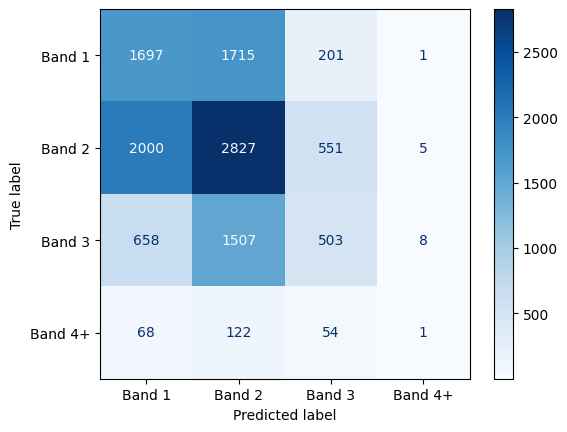

In [43]:
model_knn.fit(x_train, y_train)
valid_prediction_knn = model_knn.predict(x_valid)

print("akurasi: ", accuracy_score(y_valid, valid_prediction_knn))
print("f1_score: ", f1_score(y_valid, valid_prediction_knn, average="macro"))
print(classification_report(y_valid, valid_prediction_knn, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_prediction_knn, cmap="Blues"
)
plt.show()

In [44]:
model_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf", C=1.0, random_state=42
    ))
])

akurasi:  0.5608323544218828
f1_score:  0.41829479840284417
              precision    recall  f1-score   support

      Band 1       0.60      0.67      0.63      3614
      Band 2       0.53      0.58      0.56      5383
      Band 3       0.57      0.42      0.49      2676
     Band 4+       0.00      0.00      0.00       245

    accuracy                           0.56     11918
   macro avg       0.43      0.42      0.42     11918
weighted avg       0.55      0.56      0.55     11918



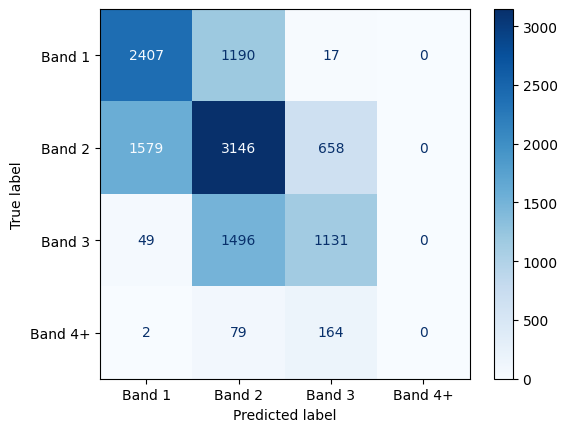

In [45]:
model_svm.fit(x_train, y_train)
valid_prediction_svm = model_svm.predict(x_valid)

print("akurasi: ", accuracy_score(y_valid, valid_prediction_svm))
print("f1_score: ", f1_score(y_valid, valid_prediction_svm, average="macro"))
print(classification_report(y_valid, valid_prediction_svm, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_prediction_svm, cmap="Blues"
)
plt.show()

In [48]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# =========================================================
# STEP 0: Definisikan base_models
# =========================================================
base_models = {
    "rf":  model_rf,
    "knn": model_knn,
    "svm": model_svm,
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =========================================================
# STEP 1: OOF predictions (label encoded)
# =========================================================
le = LabelEncoder()
le.fit(y_train)

oof_train = pd.DataFrame(index=range(len(x_train)),
                         columns=list(base_models.keys()), dtype=float)

for name, fitted_model in base_models.items():
    print(f"Training OOF: {name} ...")
    template = clone(fitted_model)
    for fold, (tr_idx, va_idx) in enumerate(skf.split(x_train, y_train), 1):
        m = clone(template)
        m.fit(x_train.iloc[tr_idx], y_train.iloc[tr_idx])
        pred = m.predict(x_train.iloc[va_idx])
        oof_train.loc[va_idx, name] = le.transform(pred)
    print(f"  ✅ {name} selesai")

# =========================================================
# STEP 2: Meta-features untuk valid  ← FIX DI SINI
# =========================================================
valid_meta = pd.DataFrame({
    "rf":  le.transform(valid_prediction_rf),
    "knn": le.transform(valid_prediction_knn),
    "svm": le.transform(valid_prediction_svm),
})[list(base_models.keys())]   # paksa urutan = rf, knn, svm

# verifikasi urutan sudah sama
assert list(oof_train.columns) == list(valid_meta.columns), \
    f"Urutan kolom beda! oof={list(oof_train.columns)}, valid={list(valid_meta.columns)}"

# =========================================================
# STEP 3: Meta-learner
# =========================================================
meta_learner = RandomForestClassifier(random_state=42)
meta_learner.fit(oof_train, y_train)

# =========================================================
# STEP 4: Evaluasi
# =========================================================
final_pred = meta_learner.predict(valid_meta)

print("Akurasi :", accuracy_score(y_valid, final_pred))
print("F1 macro:", f1_score(y_valid, final_pred, average="macro"))
print(classification_report(y_valid, final_pred, zero_division=0))

Training OOF: rf ...
  ✅ rf selesai
Training OOF: knn ...
  ✅ knn selesai
Training OOF: svm ...
  ✅ svm selesai
Akurasi : 0.5625943950327236
F1 macro: 0.4197944712462054
              precision    recall  f1-score   support

      Band 1       0.59      0.73      0.65      3614
      Band 2       0.54      0.54      0.54      5383
      Band 3       0.57      0.42      0.49      2676
     Band 4+       0.00      0.00      0.00       245

    accuracy                           0.56     11918
   macro avg       0.42      0.42      0.42     11918
weighted avg       0.55      0.56      0.55     11918



# Submission

**DILARANG MENGUBAH CODE!!!!!!!!!!!**

**Pastikan memiliki variabel berikut:**
`X_test` (hasil preprocessing dari `df_test`, **jumlah dan urutan barisnya harus sama** dengan `df_test`)

In [ ]:
# id = df_test['employee_id'].tolist()

# y_test = model_rf.predict(x_test)
# submission_df = pd.DataFrame({'employee_id': id, 'pay_band': y_test})

# assert len(submission_df) == len(df_test), 'Jumlah baris submission harus sama dengan test.csv!'
# assert set(submission_df['pay_band']) <= {'Band 1', 'Band 2', 'Band 3', 'Band 4+'}, \
#     'Isi pay_band harus label asli: Band 1 / Band 2 / Band 3 / Band 4+'

# submission_df.to_csv('submission.csv', index=False)
# submission_df.head()

,employee_id,pay_band
0,EMP-196598,Band 2
1,EMP-156920,Band 3
2,EMP-161973,Band 2
3,EMP-195108,Band 2
4,EMP-111307,Band 2


In [ ]:
# =========================================================
# Prediksi x_test dengan base models → encode → meta-learner
# =========================================================
test_pred_rf  = model_rf.predict(x_test)
test_pred_knn = model_knn.predict(x_test)
test_pred_svm = model_svm.predict(x_test)

# Encode label ke angka pakai LabelEncoder yang sama (le dari proses stacking)
test_meta = pd.DataFrame({
    "knn": le.transform(test_pred_knn),
    "svm": le.transform(test_pred_svm),
    "rf":  le.transform(test_pred_rf),
})

# Meta-learner memprediksi label asli (Band 1..Band 4+) langsung
y_test = meta_learner.predict(test_meta)

# =========================================================
# Submission
# =========================================================
id = df_test['employee_id'].tolist()
submission_df = pd.DataFrame({'employee_id': id, 'pay_band': y_test})

assert len(submission_df) == len(df_test), \
    'Jumlah baris submission harus sama dengan test.csv!'
assert set(submission_df['pay_band']) <= {'Band 1', 'Band 2', 'Band 3', 'Band 4+'}, \
    'Isi pay_band harus label asli: Band 1 / Band 2 / Band 3 / Band 4+'

submission_df.to_csv('submission_stack.csv', index=False)
print("Distribusi prediksi:")
print(submission_df['pay_band'].value_counts())
submission_df.head()